# Bluesky × Lyon — détection de topics et sujets émergents (pendant du corpus médias)

Objectif : produire, à partir de Bluesky, des **thèmes** et des **sujets émergents** construits de la même façon que pour la presse lyonnaise (K-Means + score d'émergence), plus un modèle **BERTopic** pour aller plus loin, puis une **comparaison** avec les médias.

Plan :
1. Configuration
2. Collecte (jour par jour, requêtes multiples, pagination par curseur, reprenable)
3. Construction du corpus (filtrage, dédoublonnage, bots/médias)
4. EDA
5. Nettoyage du texte
6. Topics : BERTopic (principal) + TF-IDF/K-Means (baseline comparable aux médias)
7. Évolution temporelle des topics
8. Sujets émergents (même logique que `06_emergence`)
9. Exports
10. Comparaison avec les médias (si `article_topics.parquet` est présent)

Dépendances : `pip install atproto pandas pyarrow bertopic sentence-transformers umap-learn hdbscan nltk scikit-learn matplotlib scipy`

**Fenêtre d'étude** = celle des médias (3 août → 1er novembre 2026). On collecte ~31 jours *avant* : ils servent uniquement de référence (baseline) au score d'émergence, ce qui permet de détecter des émergences dès le début de la fenêtre.

## 1. Configuration

In [10]:
import os, re, time, json, unicodedata, warnings, getpass
from pathlib import Path
from datetime import datetime, timedelta
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

# --- fenêtre d'étude (identique aux médias)
START, END = pd.Timestamp("2026-08-03"), pd.Timestamp("2026-11-01")

# --- paramètres d'émergence (identiques à 06_emergence : z >= 4, >= 6 posts, >= 2 comptes)
W, BASE = 3, 28                 # fenêtre glissante (jours) et baseline (jours)
Z_MIN, MIN_DOCS, MIN_AUTHORS = 4, 6, 2

# la collecte démarre BASE+W jours avant START (référence de l'émergence uniquement)
COLLECT_START = START - pd.Timedelta(days=BASE + W)

# --- requêtes Bluesky (à adapter) : plus il y en a, plus le corpus est large
QUERIES = [
    "lyon", "lyonnais", "lyonnaise", "métropole de lyon", "grand lyon", "villeurbanne",
    "rhône", "part-dieu", "bellecour", "croix-rousse", "vénissieux", "tcl",
]
# un post est conservé s'il évoque le territoire (comme le filtre "périmètre lyonnais" des médias)
LYON_REGEX = re.compile(
    r"lyon|villeurbann|vénissieux|venissieux|vaulx|bron\b|caluire|rhône|rhone|part-dieu|bellecour|"
    r"croix-rousse|confluence|perrache|guillotière|guillotiere|tcl\b|oullins|décines|decines|"
    r"saint-fons|givors|tassin|écully|ecully|meyzieu", re.I)

INCLUDE_REPLIES = False         # les réponses sont très conversationnelles ("ça", "oui"...) -> exclues par défaut
MIN_WORDS = 5
MAX_POSTS_PER_AUTHOR_DAY = 5    # limite l'influence d'un compte très actif
AUTO_EXCLUDE_BOTS = True        # comptes >= 50 posts dont >= 50 % contiennent une URL (médias, agrégateurs, bots)
EXCLUDE_AUTHORS = {             # à compléter après lecture du tableau "top auteurs"
    "lyonpresquile.bsky.social", "lepolitichien.bsky.social", "actusnonstop.bsky.social",
}

# --- modèles
EMB_MODEL = "paraphrase-multilingual-MiniLM-L12-v2"
TARGET_TOPICS = 30              # nb de topics BERTopic après fusion ("auto" possible)
N_KMEANS = 14                   # même k que le corpus médias, pour comparer

# --- chemins
ROOT = Path(".")
RAW = ROOT / "data" / "raw" / "bluesky"
PROC = ROOT / "data" / "processed"
FIG = ROOT / "outputs" / "figures" / "bluesky"
TAB = ROOT / "outputs" / "tables"
for p in (RAW, PROC, FIG, TAB):
    p.mkdir(parents=True, exist_ok=True)
print("Collecte :", COLLECT_START.date(), "->", END.date(), "| étude :", START.date(), "->", END.date())

Collecte : 2026-07-03 -> 2026-11-01 | étude : 2026-08-03 -> 2026-11-01


## 2. Collecte

Points importants par rapport à la version précédente :
- **le curseur est maintenant transmis** à chaque appel (avant, la même page était relue en boucle : 10 000 lignes mais seulement ~97 posts uniques) ;
- collecte **jour par jour** et **par requête** (contourne la limite de profondeur de pagination de la recherche), un fichier parquet par jour → **reprenable** ;
- **les identifiants ne sont plus dans le notebook** : variables d'environnement `BSKY_HANDLE` / `BSKY_APP_PASSWORD` (ou saisie masquée).

In [11]:
from atproto import Client

handle = os.environ.get("BSKY_HANDLE") or input("Handle Bluesky : ")
password = os.environ.get("BSKY_APP_PASSWORD") or getpass.getpass("App password : ")
client = Client()
client.login(handle, password)
print("Connecté :", handle)

Connecté : r0nard.bsky.social


In [12]:
COLS = ["uri", "author", "author_did", "text", "langs", "created_at", "likes", "reposts",
        "replies", "quotes", "is_reply", "has_embed", "query"]


def fetch_window(q, since, until, max_pages=150, pause=0.15):
    """Toutes les pages (avec curseur) d'une requête sur [since, until[."""
    rows, cursor = [], None
    for _ in range(max_pages):
        params = {"q": q, "lang": "fr", "limit": 100, "sort": "latest",
                  "since": since, "until": until}
        if cursor:
            params["cursor"] = cursor
        resp = None
        for attempt in range(6):
            try:
                resp = client.app.bsky.feed.search_posts(params=params)
                break
            except Exception as e:                      # 429, timeouts...
                wait = min(60, 2 ** attempt)
                print(f"  ! {type(e).__name__} ({q}) -> pause {wait}s")
                time.sleep(wait)
        if resp is None:
            break
        for p in resp.posts:
            rec = p.record
            rows.append({
                "uri": p.uri, "author": p.author.handle, "author_did": p.author.did,
                "text": getattr(rec, "text", "") or "",
                "langs": list(getattr(rec, "langs", None) or []),
                "created_at": getattr(rec, "created_at", None),
                "likes": p.like_count or 0, "reposts": p.repost_count or 0,
                "replies": p.reply_count or 0, "quotes": p.quote_count or 0,
                "is_reply": getattr(rec, "reply", None) is not None,
                "has_embed": getattr(rec, "embed", None) is not None,
                "query": q,
            })
        cursor = resp.cursor
        if not cursor or not resp.posts:
            break
        time.sleep(pause)
    return rows


days = pd.date_range(COLLECT_START, END, freq="D")
t0 = time.time()
for i, day in enumerate(days):
    f = RAW / f"{day:%Y-%m-%d}.parquet"
    if f.exists():
        continue                                        # déjà collecté
    since = f"{day:%Y-%m-%d}T00:00:00.000Z"
    until = f"{day + pd.Tim edelta(days=1):%Y-%m-%d}T00:00:00.000Z"
    rows = []
    for q in QUERIES:
        rows += fetch_window(q, since, until)
    day_df = pd.DataFrame(rows, columns=COLS).drop_duplicates("uri")
    day_df.to_parquet(f, index=False)
    print(f"[{i+1}/{len(days)}] {day:%Y-%m-%d} : {len(day_df):>6} posts uniques  ({time.time()-t0:,.0f}s)")

[1/122] 2026-07-03 :    123 posts uniques  (4s)
[2/122] 2026-07-04 :     67 posts uniques  (6s)
[3/122] 2026-07-05 :     66 posts uniques  (9s)
[4/122] 2026-07-06 :     82 posts uniques  (12s)
[5/122] 2026-07-07 :     89 posts uniques  (14s)
[6/122] 2026-07-08 :    100 posts uniques  (18s)
[7/122] 2026-07-09 :    107 posts uniques  (22s)
[8/122] 2026-07-10 :    135 posts uniques  (26s)
[9/122] 2026-07-11 :    187 posts uniques  (29s)
[10/122] 2026-07-12 :    181 posts uniques  (33s)
[11/122] 2026-07-13 :    202 posts uniques  (38s)
[12/122] 2026-07-14 :    185 posts uniques  (42s)
[13/122] 2026-07-15 :    196 posts uniques  (45s)
[14/122] 2026-07-16 :    187 posts uniques  (51s)
[15/122] 2026-07-17 :    208 posts uniques  (56s)
[16/122] 2026-07-18 :    181 posts uniques  (69s)
[17/122] 2026-07-19 :    154 posts uniques  (73s)
[18/122] 2026-07-20 :    170 posts uniques  (77s)
[19/122] 2026-07-21 :    181 posts uniques  (80s)
[20/122] 2026-07-22 :    171 posts uniques  (84s)
[21/122] 202

## 3. Construction du corpus

In [13]:
raw = pd.concat([pd.read_parquet(f) for f in sorted(RAW.glob("*.parquet"))], ignore_index=True)
n0 = len(raw)
raw = raw.drop_duplicates("uri")
print(f"Lignes brutes : {n0:,} -> posts uniques : {len(raw):,}")

raw["created_at"] = pd.to_datetime(raw["created_at"], utc=True, format="ISO8601", errors="coerce")
raw = raw.dropna(subset=["created_at"])
raw["date"] = raw["created_at"].dt.tz_convert("Europe/Paris").dt.tz_localize(None).dt.normalize()
raw = raw[(raw["date"] >= COLLECT_START) & (raw["date"] <= END)]

# langue française explicite
raw = raw[raw["langs"].apply(lambda l: l is not None and "fr" in list(l))]
# périmètre lyonnais (même esprit que lyon_filter.py côté médias)
raw["is_lyon"] = raw["text"].str.contains(LYON_REGEX)
raw["has_url"] = raw["text"].str.contains(r"https?://|www\.", regex=True)
print("Après langue FR :", len(raw), "| mentionnent le territoire :", int(raw["is_lyon"].sum()))

Lignes brutes : 26,282 -> posts uniques : 26,282
Après langue FR : 26100 | mentionnent le territoire : 22813


In [34]:
raw

,uri,author,author_did,text,langs,created_at,likes,reposts,replies,quotes,is_reply,has_embed,query,date,is_lyon,has_url
0,at://did:plc:buh6tnzrt3sy5mqd5mskx4zl/app.bsky.feed.post/3mprnuhcoo22c,legrugru.fr,did:plc:buh6tnzrt3sy5mqd5mskx4zl,Mais enfin c'est évident que la ville de Lyon doit être dans la même région que Belfort \n\nTu ne comprends pas le GÉNIE,[fr],2026-07-03 23:05:10.030+00:00,2,0,2,0,True,False,lyon,2026-07-04,True,False
1,at://did:plc:buh6tnzrt3sy5mqd5mskx4zl/app.bsky.feed.post/3mprnrr4f222c,legrugru.fr,did:plc:buh6tnzrt3sy5mqd5mskx4zl,Ahaha Belfort avec Lyon. \nC'est tellement logique,[fr],2026-07-03 23:03:39.648+00:00,5,0,3,0,True,False,lyon,2026-07-04,True,False
2,at://did:plc:nbya3lhze7khtc5qxt62gnuw/app.bsky.feed.post/3mprjvzvxec2j,arkanikorvo.bsky.social,did:plc:nbya3lhze7khtc5qxt62gnuw,*rigole en Cercle de l'Union à Lyon*,[fr],2026-07-03 21:54:28.126+00:00,1,0,1,0,True,False,lyon,2026-07-03,True,False
3,at://did:plc:5xka5gsgladmvz5nllklb7m6/app.bsky.feed.post/3mpria3bdes2s,sirered.bsky.social,did:plc:5xka5gsgladmvz5nllklb7m6,Fauntastic est celle que je recommande easy (elle est à Lyon en plus) :D,[fr],2026-07-03 21:24:17.608+00:00,1,0,0,0,True,False,lyon,2026-07-03,True,False
4,at://did:plc:nir4547i63s5plxcz43l3kx4/app.bsky.feed.post/3mprhdqovfc2m,colpizen.bsky.social,did:plc:nir4547i63s5plxcz43l3kx4,Up\nJ'avais complètement oublié de poster le départ de la Vanessa cardui #01 sur Paris.\nLe packaging était tout en DIY (carton récup et découpé d'après mon...,[fr],2026-07-03 21:08:26.992+00:00,25,4,2,1,False,True,lyon,2026-07-03,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26277,at://did:plc:obmeysu5klyrf7r47fgk53mt/app.bsky.feed.post/3mzadaui7cs2r,keizhac.bsky.social,did:plc:obmeysu5klyrf7r47fgk53mt,Non mais au moins j'aurais fait plus que mes pas hier ...\nLe SYTRAL sait TRES BIEN couper la desserte de certains arrêts uniquement. Le matin même seul Par...,[fr],2026-11-01 07:51:56.063+00:00,1,0,1,0,False,True,part-dieu,2026-11-01,True,False
26278,at://did:plc:7kpkdjrnxou2jsfy2k7loqst/app.bsky.feed.post/3mza5psntm224,recursiveaction.bsky.social,did:plc:7kpkdjrnxou2jsfy2k7loqst,"Tout les métros A, C et D à l'arrêt total de 13h environ jusqu'à 22h avec pour explication ""manifestation""\nLigne B ne dessert pas la Part Dieu, puis en arr...",[fr],2026-11-01 06:12:55.017+00:00,1,0,0,0,True,False,part-dieu,2026-11-01,False,False
26279,at://did:plc:j7xics3blb3ndgluebucs7eq/app.bsky.feed.post/3mzbpk3eb622l,yachn1.bsky.social,did:plc:j7xics3blb3ndgluebucs7eq,"Quant à leurs descentes, elles ne sont pas si nouvelles que ça.\nLeurs expé contre certains lieux des pentes de la Croix-Rousse non plus.\nC'est la passivit...",[fr],2026-11-01 21:04:29.902+00:00,3,0,1,0,True,False,croix-rousse,2026-11-01,True,False
26280,at://did:plc:azp4n4gq5lwfgtuljvjljmmo/app.bsky.feed.post/3mzaq4duz4x2y,coalitionnationale.bsky.social,did:plc:azp4n4gq5lwfgtuljvjljmmo,"30 % des titres de presse locale ont disparu en France depuis 2008. La menace sur Expressions à Vénissieux l'illustre. Un fonds territorialisé, financé par ...",[fr],2026-11-01 11:42:02.000+00:00,0,0,0,0,True,False,vénissieux,2026-11-01,True,False


In [14]:
# --- comptes suspects (médias, agrégateurs, bots) : posts nombreux + URL quasi systématique
stats = (raw.groupby("author")
            .agg(posts=("uri", "size"), url_share=("has_url", "mean"),
                 dup_share=("text", lambda s: 1 - s.nunique() / len(s)),
                 likes=("likes", "sum"))
            .sort_values("posts", ascending=False))
suspects = stats[(stats.posts >= 50) & ((stats.url_share >= 0.5) | (stats.dup_share >= 0.3))]
print("Top 25 auteurs :")
display(stats.head(25))
print(f"\nComptes suspects auto-détectés : {len(suspects)}")
display(suspects.head(25))

Top 25 auteurs :


,posts,url_share,dup_share,likes
author,,,,
lyonpresquile.bsky.social,10776,0.001021,0.013549,539
passagelyonnais.fr,604,0.000000,0.000000,139
quodat.bsky.social,309,1.000000,0.000000,3
actusfr.bsky.social,268,0.000000,0.000000,21
glosal-riot-korp.bsky.social,263,0.528517,0.030418,20
sports.skyfleet.blue,259,0.000000,0.000000,4
chasseurdedeals.bsky.social,181,0.000000,0.016575,12
data-ol.bsky.social,155,0.000000,0.006452,67
toulouse.bsky.social,138,0.000000,0.036232,7



Comptes suspects auto-détectés : 5


,posts,url_share,dup_share,likes
author,,,,
quodat.bsky.social,309,1.000000,0.000000,3
glosal-riot-korp.bsky.social,263,0.528517,0.030418,20
alllocalteams.bsky.social,120,0.000000,0.366667,120
lyondemain.bsky.social,96,0.875000,0.000000,77
vazektomi.bsky.social,56,0.982143,0.696429,22


In [15]:
excl = set(EXCLUDE_AUTHORS) | (set(suspects.index) if AUTO_EXCLUDE_BOTS else set())

df = raw[raw["is_lyon"] & ~raw["author"].isin(excl)].copy()
if not INCLUDE_REPLIES:
    df = df[~df["is_reply"]]
print(f"Après périmètre / exclusion comptes / réponses : {len(df):,}")

# --- texte pour les embeddings : on garde la phrase, on retire URL / mentions
def prep_text(t):
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)
    t = re.sub(r"@[\w\.\-]+", " ", t)
    t = t.replace("#", " ")
    return re.sub(r"\s+", " ", t).strip()

df["text_emb"] = df["text"].apply(prep_text)
df = df[df["text_emb"].str.split().str.len() >= MIN_WORDS]

# --- dédoublonnage : textes identiques (hors casse/ponctuation) -> on garde le plus "liké"
df["_key"] = df["text_emb"].str.lower().str.replace(r"[^\w]+", " ", regex=True).str.strip()
df = df.sort_values(["likes", "reposts"], ascending=False).drop_duplicates("_key")

# --- plafonnement par auteur et par jour
df = df.sort_values(["likes", "reposts"], ascending=False)
df["_rank"] = df.groupby(["author", "date"]).cumcount()
df = df[df["_rank"] < MAX_POSTS_PER_AUTHOR_DAY].drop(columns=["_key", "_rank"])
df = df.sort_values("created_at").reset_index(drop=True)
print(f"Corpus final : {len(df):,} posts, {df['author'].nunique():,} comptes, "
      f"{df['date'].min().date()} -> {df['date'].max().date()}")

Après périmètre / exclusion comptes / réponses : 7,446
Corpus final : 6,878 posts, 2,104 comptes, 2026-07-03 -> 2026-11-01


## 4. EDA

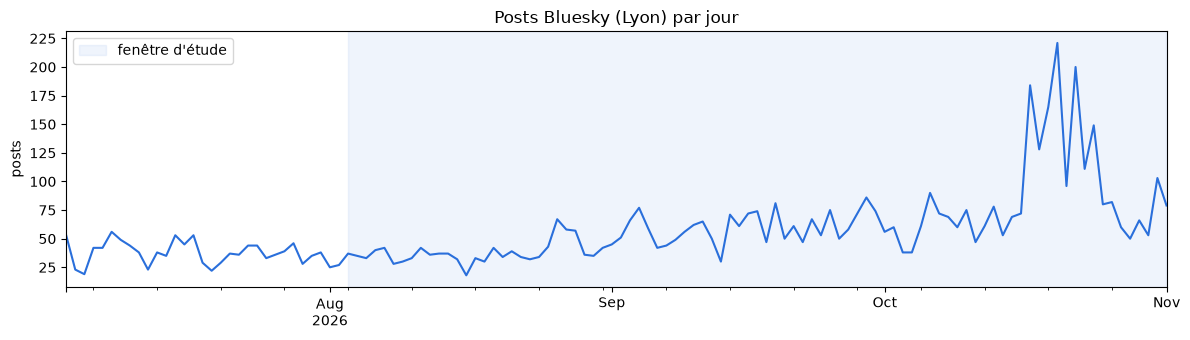

Jours à 0 post dans la fenêtre (trous éventuels de collecte) : []


In [16]:
daily = df.groupby("date").size().reindex(pd.date_range(COLLECT_START, END), fill_value=0)

fig, ax = plt.subplots(figsize=(12, 3.5))
daily.plot(ax=ax, color="#2a6fdb")
ax.axvspan(START, END, color="#2a6fdb", alpha=0.07, label="fenêtre d'étude")
ax.set_title("Posts Bluesky (Lyon) par jour"); ax.set_ylabel("posts"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "volume_quotidien.png", dpi=150); plt.show()

print("Jours à 0 post dans la fenêtre (trous éventuels de collecte) :",
      list(daily[(daily.index >= START) & (daily == 0)].index.strftime("%Y-%m-%d")))

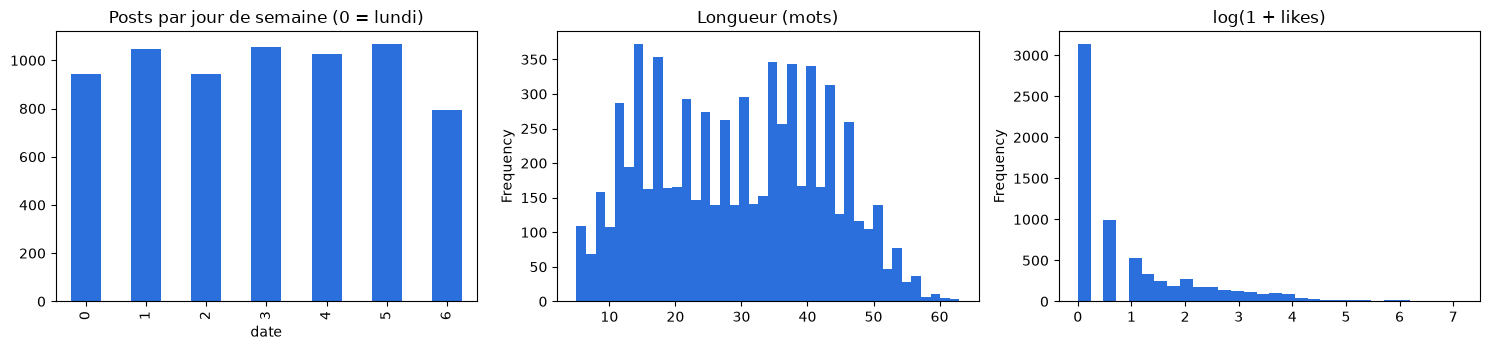

Top hashtags :


,posts
text,
lyon,1134
news,178
bonplan,168
promo,166
actu,127
presse,125
hightech,121
toulouse,82
annecy,78


Top auteurs du corpus final :


,posts
author,
passagelyonnais.fr,480
chasseurdedeals.bsky.social,166
data-ol.bsky.social,143
actusfr.bsky.social,124
memoire2cite.bsky.social,92
tchangg73.bsky.social,89
sports.skyfleet.blue,87
antyfaszysta.bsky.social,77
annecy.bsky.social,76


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
df.groupby(df["date"].dt.dayofweek).size().plot.bar(ax=axes[0], color="#2a6fdb")
axes[0].set_title("Posts par jour de semaine (0 = lundi)")
df["text_emb"].str.split().str.len().clip(upper=80).plot.hist(bins=40, ax=axes[1], color="#2a6fdb")
axes[1].set_title("Longueur (mots)")
np.log1p(df["likes"]).plot.hist(bins=30, ax=axes[2], color="#2a6fdb")
axes[2].set_title("log(1 + likes)")
fig.tight_layout(); fig.savefig(FIG / "eda_distributions.png", dpi=150); plt.show()

tags = df["text"].str.findall(r"#(\w+)").explode().str.lower().dropna()
print("Top hashtags :"); display(tags.value_counts().head(20).to_frame("posts"))
print("Top auteurs du corpus final :")
display(df["author"].value_counts().head(15).to_frame("posts"))

## 5. Nettoyage du texte

Même pipeline que pour les médias (sans accents, stopwords NLTK + stopwords métier), utilisé pour **TF-IDF, K-Means et l'émergence**. Les **embeddings** de BERTopic utilisent `text_emb` (phrase conservée), plus fidèle sémantiquement.

In [18]:
import nltk
from nltk.corpus import stopwords
try:
    raw_nltk = stopwords.words("french")
except LookupError:
    nltk.download("stopwords"); raw_nltk = stopwords.words("french")


def remove_accents(s):
    return "".join(c for c in unicodedata.normalize("NFKD", s) if not unicodedata.combining(c))


custom = {
    "lyon", "lyonnais", "lyonnaise", "france", "octobre", "septembre", "aout", "novembre", "2026", "2025",
    "www", "com", "fr", "http", "https", "html", "url", "amp", "bluesky", "bsky", "social", "via",
    "tout", "tous", "cette", "fait", "sont", "ont", "est", "ete", "etre", "plus", "aussi", "comme",
    "tres", "bien", "peut", "faire", "alors", "encore", "juste", "quand", "veut", "faut", "voir",
    "ca", "cest", "jai", "nest", "dun", "dune", "mdr", "lol", "ptdr",
}
STOP_NOACC = {remove_accents(w) for w in raw_nltk} | custom
STOP_ACC = set(raw_nltk) | {w for w in custom} | STOP_NOACC     # pour les vectoriseurs sur texte accentué


def clean_text(text):
    t = remove_accents(str(text).lower())
    t = re.sub(r"http\S+|www\S+", " ", t)
    t = re.sub(r"@[\w\.\-]+", " ", t)
    t = re.sub(r"['’\-–—]", " ", t)
    t = re.sub(r"[^\w\s]", " ", t)
    return " ".join(w for w in t.split() if w not in STOP_NOACC and not w.isdigit() and len(w) >= 3)


df["texte_clean"] = df["text"].apply(clean_text)
df = df[df["texte_clean"].str.split().str.len() >= 3].reset_index(drop=True)
print(f"{len(df):,} posts après nettoyage")
df[["text", "texte_clean"]].sample(5, random_state=SEED)

6,808 posts après nettoyage


,text,texte_clean
4866,🥰🥰🥰Coucouuu touut le monnde ! 🥰🥰🥰nous sommes j...,coucouuu touut monnde jerdi comment allez aujo...
1323,Long Distance Calling en France les 31/10 (Par...,long distance calling paris
2470,69 - CHAT TROUVÉ \nJ'ai trouvé ce chaton avenu...,chat trouve trouve chaton avenue leclerc deux ...
4233,Prochaine permanence collective: Prépare ta pr...,prochaine permanence collective prepare pride ...
3837,🚨 INFO EXCLUSIVE 🚨\n\nAnticipant leur retour s...,info exclusive anticipant retour ronds points ...


## 6. Topics

### 6.1 Embeddings (mis en cache sur disque)

In [19]:
from sentence_transformers import SentenceTransformer

EMB_FILE = PROC / "bluesky_embeddings.npy"
IDX_FILE = PROC / "bluesky_embeddings_uris.npy"
st_model = SentenceTransformer(EMB_MODEL)

emb = None
if EMB_FILE.exists() and IDX_FILE.exists():                # réutilise le cache si le corpus est identique
    cached_uris = np.load(IDX_FILE, allow_pickle=True)
    if len(cached_uris) == len(df) and (cached_uris == df["uri"].values).all():
        emb = np.load(EMB_FILE)
        print("Embeddings chargés depuis le cache :", emb.shape)
if emb is None:
    emb = st_model.encode(df["text_emb"].tolist(), batch_size=64, show_progress_bar=True,
                          normalize_embeddings=True)
    np.save(EMB_FILE, emb); np.save(IDX_FILE, df["uri"].values, allow_pickle=True)
    print("Embeddings calculés :", emb.shape)

Batches: 100%|██████████| 107/107 [01:10<00:00,  1.53it/s]

Embeddings calculés : (6808, 384)


### 6.2 BERTopic (modèle principal)

Différences avec le premier essai : colonne de texte correcte (`texte_clean` n'existait pas sous le nom `text_clean`), embeddings pré-calculés, UMAP/HDBSCAN seedés (reproductible), `min_cluster_size` proportionnel à la taille du corpus, fusion à `TARGET_TOPICS` thèmes, réduction des outliers, mots-clés diversifiés (MMR) avec bigrammes.

In [20]:
from bertopic import BERTopic
from bertopic.representation import MaximalMarginalRelevance
from sklearn.feature_extraction.text import CountVectorizer
from umap import UMAP
from hdbscan import HDBSCAN

docs = df["text_emb"].tolist()
min_cluster = max(15, int(len(df) * 0.002))
print("min_cluster_size =", min_cluster)

umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=SEED)
hdbscan_model = HDBSCAN(min_cluster_size=min_cluster, min_samples=5, metric="euclidean",
                        cluster_selection_method="eom", prediction_data=True)
vectorizer = CountVectorizer(stop_words=sorted(STOP_ACC), ngram_range=(1, 2), min_df=5,
                             token_pattern=r"(?u)\b[^\W\d_]{3,}\b")
representation = MaximalMarginalRelevance(diversity=0.4)

topic_model = BERTopic(embedding_model=st_model, umap_model=umap_model, hdbscan_model=hdbscan_model,
                       vectorizer_model=vectorizer, representation_model=representation,
                       calculate_probabilities=False, verbose=True)
topics, _ = topic_model.fit_transform(docs, embeddings=emb)
print("Topics bruts :", len(set(topics)) - 1, "| outliers :", f"{np.mean(np.array(topics) == -1):.0%}")

2026-11-08 02:31:08,284 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm


min_cluster_size = 15


2026-11-08 02:31:49,279 - BERTopic - Dimensionality - Completed ✓
2026-11-08 02:31:49,280 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-11-08 02:31:49,446 - BERTopic - Cluster - Completed ✓
2026-11-08 02:31:49,450 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-11-08 02:31:55,688 - BERTopic - Representation - Completed ✓


Topics bruts : 101 | outliers : 41%


In [21]:
# fusion des topics proches
if TARGET_TOPICS and len(set(topics)) - 1 > TARGET_TOPICS:
    topic_model.reduce_topics(docs, nr_topics=TARGET_TOPICS)
    topics = topic_model.topics_

df["topic_raw"] = topics                                   # avec outliers (-1)

# réaffectation des outliers au topic le plus proche (embeddings)
new_topics = topic_model.reduce_outliers(docs, topics, strategy="embeddings", embeddings=emb, threshold=0.35)
topic_model.update_topics(docs, topics=new_topics, vectorizer_model=vectorizer,
                          representation_model=representation)
df["topic"] = new_topics
df["is_outlier_reassigned"] = (df["topic_raw"] == -1) & (df["topic"] != -1)
print("Topics finaux :", df.loc[df.topic >= 0, "topic"].nunique(),
      "| outliers restants :", f"{(df.topic == -1).mean():.0%}")

2026-11-08 02:31:56,138 - BERTopic - Topic reduction - Reducing number of topics
2026-11-08 02:31:56,161 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-11-08 02:31:58,287 - BERTopic - Representation - Completed ✓
2026-11-08 02:31:58,291 - BERTopic - Topic reduction - Reduced number of topics from 102 to 30
2026-11-08 02:31:58,530 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


Topics finaux : 29 | outliers restants : 1%


In [22]:
info = topic_model.get_topic_info()
info = info[info.Topic >= 0].copy()
info["top_terms"] = info["Topic"].apply(lambda t: ", ".join(w for w, _ in topic_model.get_topic(t)[:8]))
info["label"] = info.apply(lambda r: f"T{r.Topic} · " + ", ".join(r.top_terms.split(", ")[:3]), axis=1)
info["share"] = info["Count"] / info["Count"].sum()
LABELS = dict(zip(info.Topic, info.label))
df["topic_label"] = df["topic"].map(LABELS).fillna("hors-topic")

# exemples les plus "représentatifs" (proches du centroïde) et les plus likés
def examples(t, n=2):
    sub = df[df.topic == t]
    c = emb[sub.index].mean(0)
    best = sub.assign(sim=emb[sub.index] @ c / np.linalg.norm(c)).nlargest(n, "sim")["text_emb"]
    return " || ".join(x[:140] for x in best)

info["exemples"] = info["Topic"].apply(examples)
pd.set_option("display.max_colwidth", 160)
display(info[["Topic", "Count", "share", "top_terms", "exemples"]].sort_values("Count", ascending=False))

,Topic,Count,share,top_terms,exemples
1,0,1045,0.155022,"manifestation, extrême droite, manifestations, feu, manifestants, rassemblement, violences, mobilisation","Manifestations du 17 octobre: des premières actions à Lyon, Rennes et Lille, 40 interpellations dans l'agglomération parisienne || [Politique] «Ils ont agi ..."
2,1,1024,0.151906,"métropole, paris, climatique, place, capitale, aujourd hui, nice, demain","Rennes au complet et avec des retouches pour le déplacement à Lyon || Sur Lyon et sa région, au gré des balades"
3,2,679,0.100727,"match, olympique, psg, sport, club, news presse, équipe, rennes","Ligue 1: vainqueur d'Auxerre, Lyon déjà aux avant-postes || Ligue 1 : Lyon s'impose dans le derby, le Paris FC enflamme Jean-Bouin et Lorient surprend Monac..."
5,4,638,0.094645,"musée, festival, art, exposition, culture, villeurbanne, caen, artistes",🚉 Inauguration de l’exposition « Gares aux Gaulois ! » à la Gare de Lyon avec les aménageurs et partenaires de l’Inrap. 📅 À découvrir jusqu’ || Lyon : de Do...
4,3,418,0.062009,"vigilance, bouches rhône, orange, vallée rhône, météo, nuit, office tourisme, incendies","‼️ [ 🇫🇷 FRANCE ] 🔸 Un couvre-feu est instauré dans l’hypercentre de Lyon, de 21 h à 6 h du matin. || 🟠7 départements en Vigilance orange canicule : épisode ..."
11,10,350,0.051921,"soirée, chez, aujourd hui, deux, vidéo, être, merci, villeurbanne",Pancartes de la manif lyonnaise du jour... || Comment ca calme ? Des neo nazls ont défilé a Lyon
10,9,287,0.042575,"eau, région auvergne, vallée rhône, bouches rhône, site, rhone alpes, auvergne rhone, découverte","Les ""Vignes héroïques"" de la vallée du Rhône septentrionale, toute une histoire depuis 2000 ans france3-regions.franceinfo.fr/auvergne-rho.. || Département ..."
7,6,277,0.041092,"train, métropole, métro, sncf, bus, transports, mobilité, voitures",Plus que deux jours pour renseigner les points de blocage à vélo sur la Métropole de Lyon : jeparticipe.grandlyon.com/project/ca-b... || ❌Rénover intégralem...
9,8,260,0.038570,"lycéens, étudiants, enfants, écoles, mobilisation, manifestation, lycéenne, femmes","⭕Un monde dingue à Lyon pour la manifestation des lycéens, étudiants et les soutiens à la jeunesse ! Tribune-Populaire || Manifestation lycéenne à Lyon : su..."
12,11,235,0.034861,"institut, programme, handicap, conférence, cnrs, ateliers, association, données","🤝 ON HEALTH devient partenaire de Lyonbiopôle Auvergne-Rhône-Alpes ! Nous couvrirons la Journée Collaborative 2026 le 13 octobre à Lyon, un || ⏱️J-7 avant ..."


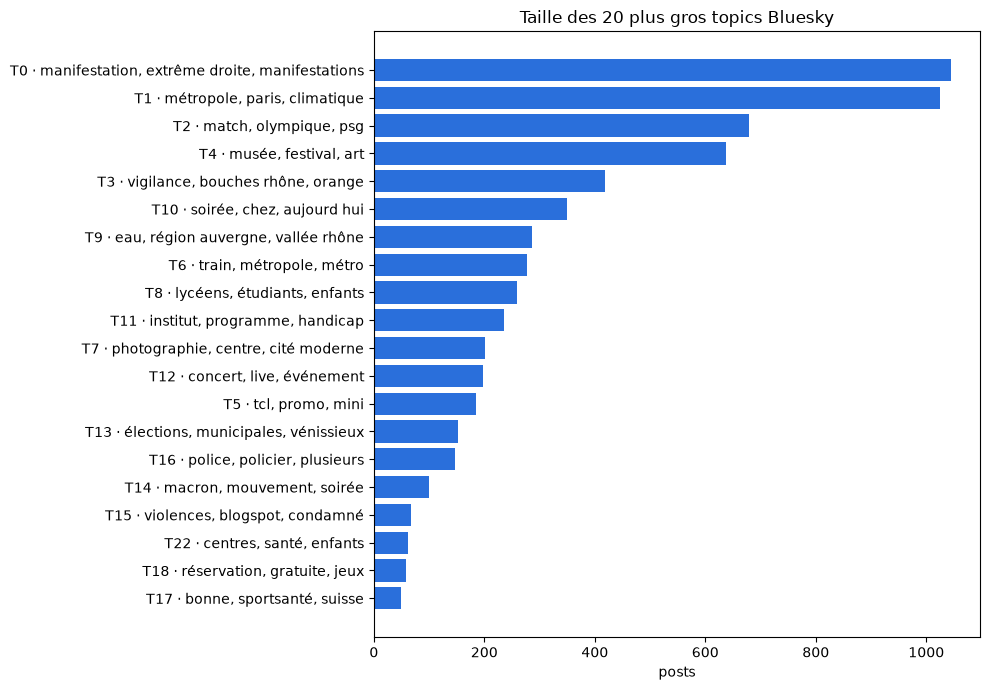

In [23]:
top = info.sort_values("Count", ascending=True).tail(20)
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top["label"], top["Count"], color="#2a6fdb")
ax.set_title("Taille des 20 plus gros topics Bluesky"); ax.set_xlabel("posts")
fig.tight_layout(); fig.savefig(FIG / "topics_taille.png", dpi=150); plt.show()

### 6.3 Baseline TF-IDF + K-Means (comparable aux thèmes médias)

Même méthode et même `k` que côté médias ; on mesure aussi la stabilité (ARI entre graines) pour pouvoir dire si BERTopic est plus stable que K-Means.

In [24]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

tfidf = TfidfVectorizer(min_df=5, max_df=0.5, ngram_range=(1, 2), sublinear_tf=True)
Xt = tfidf.fit_transform(df["texte_clean"])
terms = np.array(tfidf.get_feature_names_out())
print("Matrice TF-IDF :", Xt.shape)

km = KMeans(n_clusters=N_KMEANS, n_init=10, random_state=SEED).fit(Xt)
df["kmeans"] = km.labels_
sil = silhouette_score(Xt, km.labels_, sample_size=min(5000, len(df)), random_state=SEED)
labs = [KMeans(n_clusters=N_KMEANS, n_init=3, random_state=s).fit(Xt).labels_ for s in (1, 2, 3)]
ari = np.mean([adjusted_rand_score(km.labels_, l) for l in labs])
print(f"silhouette = {sil:.3f} | stabilité ARI moyenne = {ari:.2f}")

rows = []
for k in range(N_KMEANS):
    top_idx = km.cluster_centers_[k].argsort()[::-1][:8]
    rows.append({"kmeans": k, "posts": int((km.labels_ == k).sum()), "top_terms": ", ".join(terms[top_idx])})
km_info = pd.DataFrame(rows).sort_values("posts", ascending=False)
display(km_info)

# --- accord BERTopic / K-Means (ARI sur les posts hors outliers)
mask = df["topic"] >= 0
print("ARI BERTopic vs K-Means :", round(adjusted_rand_score(df.loc[mask, "topic"], df.loc[mask, "kmeans"]), 3))

Matrice TF-IDF : (6808, 4976)
silhouette = 0.016 | stabilité ARI moyenne = 0.53


,kmeans,posts,top_terms
10,10,4197,"apres, place, deux, ville, ans, gare, samedi, manifestation"
11,11,630,"rhone, bouches rhone, bouches, photographer, monochrome, vallee, vallee rhone, ville"
4,4,400,"paris, toulouse, marseille, paris marseille, bordeaux, lille, rennes, nantes"
7,7,234,"ligue, champions, ligue champions, europa, fenerbahce, saison, league, openda"
3,3,221,"metropole, droite, sarselli, projet, veronique, veronique sarselli, velo, rive droite"
8,8,205,"villeurbanne, gratte, gratte ciel, ciel, rue, egalite, ans, depuis"
9,9,186,"rhone alpes, alpes, auvergne rhone, auvergne, rhone, region, region auvergne, annecy"
6,6,155,"bonplan, promo, tcl, bonplan hightech, hightech promo, hightech, mini, led"
1,1,125,"actu news, news presse, presse, actu, news, sport actu, rmc, rmcsport"
5,5,119,"aujourd hui, aujourd, hui, ville, rhone, demain, villeurbanne, greve"


ARI BERTopic vs K-Means : 0.03


## 7. Évolution temporelle des topics

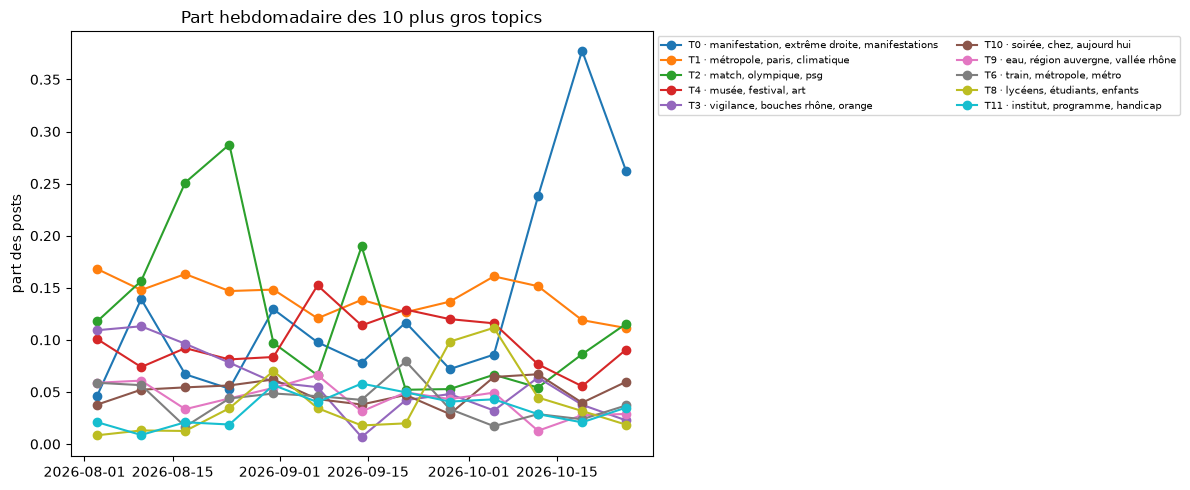

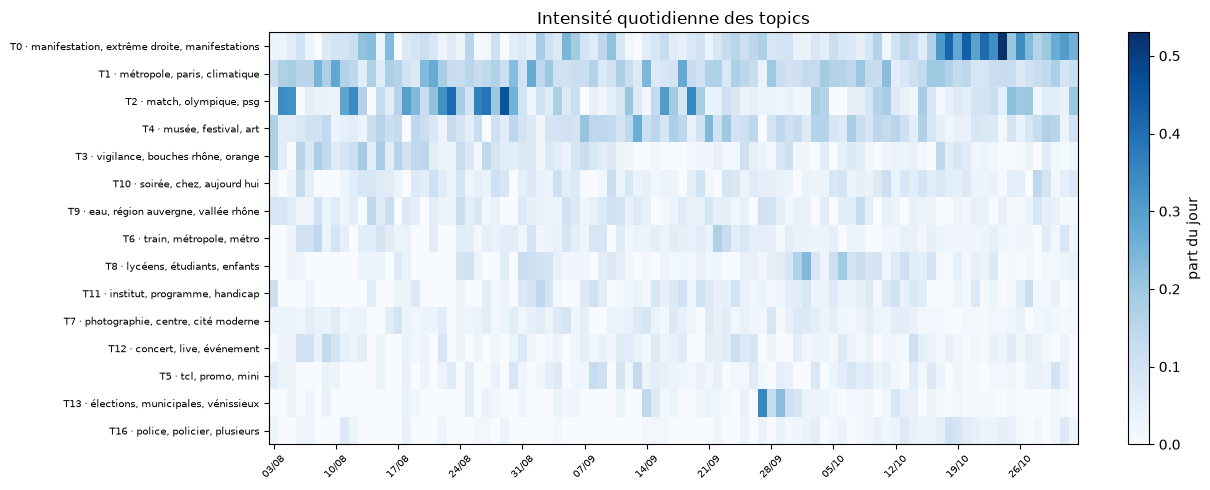

In [25]:
study = df[(df["date"] >= START) & (df["date"] <= END) & (df["topic"] >= 0)].copy()
study["week"] = study["date"].dt.to_period("W").dt.start_time

weekly = study.groupby(["week", "topic"]).size().unstack(fill_value=0)
weekly_share = weekly.div(weekly.sum(1), axis=0)

top10 = info.sort_values("Count", ascending=False).Topic.head(10).tolist()
fig, ax = plt.subplots(figsize=(12, 5))
for t in top10:
    ax.plot(weekly_share.index, weekly_share[t], marker="o", label=LABELS[t])
ax.set_title("Part hebdomadaire des 10 plus gros topics"); ax.set_ylabel("part des posts")
ax.legend(fontsize=7, ncol=2, loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout(); fig.savefig(FIG / "topics_hebdo.png", dpi=150); plt.show()

# heatmap journalière (part du jour), 15 topics
daily_topic = study.groupby(["date", "topic"]).size().unstack(fill_value=0)
daily_share = daily_topic.div(daily_topic.sum(1), axis=0)
top15 = info.sort_values("Count", ascending=False).Topic.head(15).tolist()
fig, ax = plt.subplots(figsize=(13, 5))
im = ax.imshow(daily_share[top15].T.values, aspect="auto", cmap="Blues")
ax.set_yticks(range(len(top15))); ax.set_yticklabels([LABELS[t] for t in top15], fontsize=7)
ticks = np.arange(0, len(daily_share), 7)
ax.set_xticks(ticks); ax.set_xticklabels(daily_share.index[ticks].strftime("%d/%m"), rotation=45, fontsize=7)
fig.colorbar(im, ax=ax, label="part du jour"); ax.set_title("Intensité quotidienne des topics")
fig.tight_layout(); fig.savefig(FIG / "topics_heatmap_jour.png", dpi=150); plt.show()

## 8. Sujets émergents

Même logique que côté médias : pour chaque terme (unigrammes + bigrammes), score
`z = (observé − attendu) / √(attendu + 1)` sur une fenêtre glissante de `W` jours, l'attendu venant du taux des `BASE` jours précédents. Retenu si `z ≥ 4`, `≥ 6 posts` et `≥ 2 comptes` distincts (au lieu de ≥ 2 médias). Les termes sont ensuite regroupés en **événements** par recouvrement des posts concernés (Jaccard).

In [26]:
from scipy import sparse

cv_e = CountVectorizer(binary=True, min_df=MIN_DOCS, ngram_range=(1, 2),
                       token_pattern=r"(?u)\b[a-z]{3,}\b")
Xe = cv_e.fit_transform(df["texte_clean"]).tocsc()
vocab = np.array(cv_e.get_feature_names_out())

all_days = pd.date_range(COLLECT_START, END, freq="D")
day_idx = df["date"].map({d: i for i, d in enumerate(all_days)}).values.astype(int)
D = len(all_days)
Dm = sparse.csr_matrix((np.ones(len(df)), (np.arange(len(df)), day_idx)), shape=(len(df), D))
C = (Xe.T @ Dm).toarray()                        # termes x jours (nb de posts contenant le terme)
N = np.bincount(day_idx, minlength=D).astype(float)

Z = np.full_like(C, -np.inf, dtype=float)
OBS = np.zeros_like(C, dtype=float)
for d in range(BASE + W - 1, D):
    b0, b1 = d - W - BASE + 1, d - W + 1          # jours de baseline : b0 .. d-W
    base_rate = C[:, b0:b1].sum(1) / max(N[b0:b1].sum(), 1)
    obs = C[:, d - W + 1:d + 1].sum(1)
    exp = base_rate * N[d - W + 1:d + 1].sum()
    Z[:, d] = (obs - exp) / np.sqrt(exp + 1)
    OBS[:, d] = obs

study_days = np.where((all_days >= START) & (all_days <= END))[0]
cands = []
for t in range(len(vocab)):
    zs = np.where(OBS[t, study_days] >= MIN_DOCS, Z[t, study_days], -np.inf)
    j = int(np.argmax(zs))
    if zs[j] >= Z_MIN:
        d = study_days[j]
        docs_in = np.where((day_idx > d - W) & (day_idx <= d))[0]
        docs_in = docs_in[Xe[docs_in, t].toarray().ravel() > 0]
        n_auth = df["author"].iloc[docs_in].nunique()
        if n_auth >= MIN_AUTHORS:
            cands.append({"term": vocab[t], "peak_date": all_days[d], "z": zs[j],
                          "n_posts": len(docs_in), "n_authors": n_auth, "_docs": set(docs_in)})
emerg = pd.DataFrame(cands).sort_values("z", ascending=False).reset_index(drop=True)
print(f"{len(emerg)} termes émergents (z >= {Z_MIN}, >= {MIN_DOCS} posts, >= {MIN_AUTHORS} comptes)")
display(emerg.drop(columns="_docs").head(30))

405 termes émergents (z >= 4, >= 6 posts, >= 2 comptes)


,term,peak_date,z,n_posts,n_authors
0,couvre,2026-10-21,103.000000,103,90
1,couvre feu,2026-10-21,90.000000,90,81
2,office tourisme,2026-10-19,48.000000,48,41
3,office,2026-10-19,45.050001,51,43
4,tourisme,2026-10-19,38.293283,48,41
5,feu,2026-10-21,36.932477,95,83
6,defilent,2026-10-21,24.849856,28,27
7,limoges,2026-10-19,21.000000,21,19
8,manifester,2026-10-24,20.623905,46,40
9,incendie,2026-10-19,20.543880,26,22


In [27]:
from sklearn.cluster import AgglomerativeClustering

def jaccard_matrix(sets):
    n = len(sets); M = np.zeros((n, n))
    for i in range(n):
        for j in range(i, n):
            u = len(sets[i] | sets[j])
            M[i, j] = M[j, i] = (len(sets[i] & sets[j]) / u) if u else 0
    return M

evt_rows, events = [], pd.DataFrame()
if len(emerg) >= 2:
    sub = emerg.head(600)                                      # borne le coût de la matrice
    sets = sub["_docs"].tolist()
    dist = 1 - jaccard_matrix(sets)
    try:
        agg = AgglomerativeClustering(n_clusters=None, metric="precomputed", linkage="average",
                                      distance_threshold=0.8)
    except TypeError:                                          # sklearn < 1.2
        agg = AgglomerativeClustering(n_clusters=None, affinity="precomputed", linkage="average",
                                      distance_threshold=0.8)
    sub = sub.assign(event=agg.fit_predict(dist))

    for ev, g in sub.groupby("event"):
        g = g.sort_values("z", ascending=False)
        union = sorted(set().union(*g["_docs"]))
        ex = df.iloc[union].nlargest(2, "likes")["text_emb"].str[:140].tolist()
        evt_rows.append({
            "event": ev, "label": ", ".join(g["term"].head(5)), "n_terms": len(g),
            "n_posts": len(union), "n_authors": df["author"].iloc[union].nunique(),
            "peak_date": g["peak_date"].iloc[0].date(), "z_max": round(g["z"].iloc[0], 1),
            "main_topic": df["topic_label"].iloc[union].mode().iloc[0],
            "exemples": " || ".join(ex), "_docs": set(union),
        })
    events = pd.DataFrame(evt_rows).sort_values("z_max", ascending=False).reset_index(drop=True)
    print(f"{len(events)} événements")
    display(events.drop(columns="_docs").head(25))
else:
    print("Pas assez de termes émergents : vérifier la collecte ou assouplir Z_MIN / MIN_DOCS.")

201 événements


,event,label,n_terms,n_posts,n_authors,peak_date,z_max,main_topic,exemples
0,42,"couvre, couvre feu, feu",3,107,92,2026-10-21,103.0,"T0 · manifestation, extrême droite, manifestations","Alors qu’à Lyon, un couvre-feu est instauré, interdisant tout rassemblement, des hordes néonazies se baladent tranquillement dans les rues d || Tranquillou,..."
1,178,"office tourisme, office, tourisme, incendie",4,55,46,2026-10-19,48.0,"T3 · vigilance, bouches rhône, orange","Macron et Lecornu dénoncent une ""violence d'une extrême intensité"": l'office de tourisme de Lyon a été incendié, de même que la mairie de Li || Un sympathis..."
2,17,"defilent, nazis, nazis defilent",3,43,39,2026-10-21,24.8,"T0 · manifestation, extrême droite, manifestations","""Ouin ouin les poticommerces"" Quand la librairie ""La Plume Noire"" à Lyon s'est faite attaquer et saccager par un groupe de néo-nazis (Ouest || Il est curie..."
3,88,"limoges, mairie, mairie limoges",3,28,26,2026-10-19,21.0,"T0 · manifestation, extrême droite, manifestations","Macron et Lecornu dénoncent une ""violence d'une extrême intensité"": l'office de tourisme de Lyon a été incendié, de même que la mairie de Li || Travail Fami..."
4,196,manifester,1,46,40,2026-10-24,20.6,"T0 · manifestation, extrême droite, manifestations","Si on résume, les seuls qui auront pu manifester à Lyon en huit jours, ce sont les néonazis. || Le préfet des Bouches-du-Rhône suspend totalement les transp..."
5,1,"defile, plein couvre, plein",3,34,32,2026-10-21,20.4,"T0 · manifestation, extrême droite, manifestations","« Les règles doivent être les mêmes pour tous. » Le maire de Lyon, Grégory Doucet, monte au créneau après le défilé d’une centaine de milita || - Il y a eu ..."
6,22,"anderlecht, europa, europa league, ligue europa, league",5,35,17,2026-09-17,17.9,"T2 · match, olympique, psg",🔴⚫ Franck Haise a convoqué 26 joueurs pour le match du Stade Rennais à Graz en Europa League mercredi puis le stage en Slovénie et le match || Au moins 2 L...
7,126,psg,1,24,13,2026-10-27,16.0,"T2 · match, olympique, psg",C’EST TER-MI-NÉ ! ⏱️ Le PSG s’impose 2-0 face à Lyon avec un but de Senny Mayulu et le premier au PSG de Mika Godts ! ❤️💙 Paris prend aussi || Si le score ...
8,15,"olsrfc, rennais, stade rennais, stade",4,20,10,2026-09-20,16.0,"T2 · match, olympique, psg","Un naufrage absolu pour le Stade rennais à Lyon, avec les choix difficilement compréhensibles de Franck Haise et une noyade technique et tac || 🔴⚫ Le groupe..."
9,179,toulouse,1,25,8,2026-08-23,15.6,"T2 · match, olympique, psg",L1 - J1 / Toulouse FC - OL : Fonseca et Tolisso s'expriment devant les médias - Ferveur Lyonnaise (Ferveur Lyonnaise) Toulouse || L1 - J1 / Toulouse FC - OL...


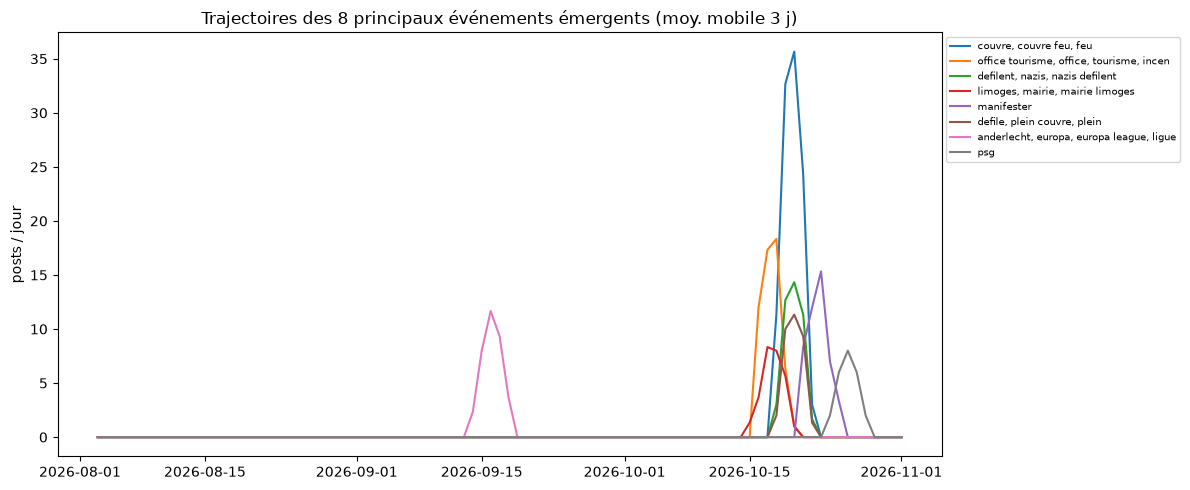

In [28]:
if len(events):
    top_ev = events.head(8)
    fig, ax = plt.subplots(figsize=(12, 5))
    for _, r in top_ev.iterrows():
        idx = sorted(r["_docs"])
        s = df.iloc[idx].groupby("date").size().reindex(pd.date_range(START, END), fill_value=0)
        ax.plot(s.rolling(3, center=True, min_periods=1).mean(), label=r["label"][:40])
    ax.set_title("Trajectoires des 8 principaux événements émergents (moy. mobile 3 j)")
    ax.set_ylabel("posts / jour"); ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1, 1))
    fig.tight_layout(); fig.savefig(FIG / "evenements_trajectoires.png", dpi=150); plt.show()

## 9. Exports (entrées de la comparaison)

In [29]:
out_cols = ["uri", "author", "date", "created_at", "text", "text_emb", "texte_clean", "likes", "reposts",
            "topic", "topic_raw", "topic_label", "kmeans"]
df[out_cols].to_parquet(PROC / "bluesky_article_topics.parquet", index=False)
info.drop(columns=["Representative_Docs"], errors="ignore").to_csv(TAB / "bluesky_topics.csv", index=False)
km_info.to_csv(TAB / "bluesky_kmeans_themes.csv", index=False)
emerg.drop(columns="_docs").to_csv(TAB / "bluesky_termes_emergents.csv", index=False)
if len(events):
    events.drop(columns="_docs").to_csv(TAB / "bluesky_evenements.csv", index=False)
    pd.DataFrame({r["event"]: df.iloc[sorted(r["_docs"])].groupby("date").size()
                  for _, r in events.iterrows()}).reindex(pd.date_range(START, END)).fillna(0)\
        .to_csv(TAB / "bluesky_evenements_serie_quotidienne.csv")
daily_topic.to_csv(TAB / "bluesky_topics_serie_quotidienne.csv")
try:
    topic_model.save(str(PROC / "bertopic_bluesky"), serialization="safetensors",
                     save_ctfidf=True, save_embedding_model=EMB_MODEL)
except Exception as e:
    print("Sauvegarde du modèle BERTopic ignorée :", e)
print("Exports OK ->", PROC, "et", TAB)

Exports OK -> data\processed et outputs\tables


## 10. Comparaison avec les médias

Nécessite `data/processed/article_topics.parquet` (produit par `05_themes.ipynb`). Trois lectures :
1. **Proximité sémantique** : similarité cosinus entre les centroïdes des topics Bluesky et ceux des thèmes médias (même modèle d'embeddings) ;
2. **Synchronie** : corrélation des séries quotidiennes pour les paires appariées, et **décalage** (qui parle d'un sujet en premier : Bluesky ou les médias ?) ;
3. **Couverture** : part du volume Bluesky dont le thème n'a pas d'équivalent proche côté médias (et inversement).

Si les noms de colonnes de votre fichier diffèrent, ajustez `MEDIA_*` ci-dessous.

In [30]:
MEDIA_PATH = PROC / "article_topics.parquet"
MEDIA_DATE, MEDIA_TEXT, MEDIA_TOPIC = None, None, None        # None = détection automatique
SIM_MATCH = 0.45                                              # seuil de "même sujet"

media = pd.read_parquet(MEDIA_PATH) if MEDIA_PATH.exists() else None
if media is None:
    print("Fichier médias introuvable :", MEDIA_PATH, "-> section ignorée.")
else:
    pick = lambda given, cands: given or next((c for c in cands if c in media.columns), None)
    MEDIA_DATE = pick(MEDIA_DATE, ["date", "date_pub", "published", "datetime", "seendate"])
    MEDIA_TEXT = pick(MEDIA_TEXT, ["title", "titre", "titre_clean", "title_clean", "text"])
    MEDIA_TOPIC = pick(MEDIA_TOPIC, ["kmeans", "theme", "cluster", "topic", "kmeans_label"])
    print("Colonnes médias retenues :", MEDIA_DATE, MEDIA_TEXT, MEDIA_TOPIC)
    assert all([MEDIA_DATE, MEDIA_TEXT, MEDIA_TOPIC]), "Renseignez MEDIA_DATE / MEDIA_TEXT / MEDIA_TOPIC."
    media = media.copy()
    media["date"] = pd.to_datetime(media[MEDIA_DATE]).dt.tz_localize(None).dt.normalize() \
        if pd.to_datetime(media[MEDIA_DATE]).dt.tz is not None else pd.to_datetime(media[MEDIA_DATE]).dt.normalize()
    media = media[(media["date"] >= START) & (media["date"] <= END)].dropna(subset=[MEDIA_TEXT, MEDIA_TOPIC])
    print(f"{len(media):,} articles médias dans la fenêtre")

Fichier médias introuvable : data\processed\article_topics.parquet -> section ignorée.


In [31]:
if media is not None:
    m_emb = st_model.encode(media[MEDIA_TEXT].astype(str).tolist(), batch_size=64,
                            show_progress_bar=True, normalize_embeddings=True)

    def centroids(E, labels):
        keys = sorted(pd.Series(labels).unique())
        C_ = np.vstack([E[np.asarray(labels) == k].mean(0) for k in keys])
        return keys, C_ / np.linalg.norm(C_, axis=1, keepdims=True)

    in_study = (df["date"] >= START) & (df["date"] <= END) & (df["topic"] >= 0)
    b_keys, b_cent = centroids(emb[in_study.values], df.loc[in_study, "topic"].values)
    m_keys, m_cent = centroids(m_emb, media[MEDIA_TOPIC].values)
    S = b_cent @ m_cent.T                                       # topics Bluesky x thèmes médias

    # libellés médias : top termes du thème (si dispo) sinon identifiant
    m_labels = {k: f"M{k}" for k in m_keys}
    sim_df = pd.DataFrame(S, index=[LABELS[k] for k in b_keys], columns=[m_labels[k] for k in m_keys])

    fig, ax = plt.subplots(figsize=(10, 10))
    im = ax.imshow(S, cmap="viridis", aspect="auto")
    ax.set_yticks(range(len(b_keys))); ax.set_yticklabels(sim_df.index, fontsize=6)
    ax.set_xticks(range(len(m_keys))); ax.set_xticklabels(sim_df.columns, rotation=90, fontsize=7)
    fig.colorbar(im, ax=ax, label="similarité cosinus"); ax.set_title("Topics Bluesky × thèmes médias")
    fig.tight_layout(); fig.savefig(FIG / "comparaison_similarite.png", dpi=150); plt.show()

In [32]:
if media is not None:
    rng = pd.date_range(START, END)
    b_counts = df[in_study].groupby(["date", "topic"]).size().unstack(fill_value=0).reindex(rng, fill_value=0)
    m_counts = media.groupby(["date", MEDIA_TOPIC]).size().unstack(fill_value=0).reindex(rng, fill_value=0)
    b_share = b_counts.div(b_counts.sum(1).replace(0, np.nan), axis=0).fillna(0)
    m_share = m_counts.div(m_counts.sum(1).replace(0, np.nan), axis=0).fillna(0)

    def lagcorr(a, b, maxlag=7):
        """corr(a_t, b_{t+lag}) : lag > 0 => a (Bluesky) précède b (médias)."""
        res = {l: a.corr(b.shift(-l)) for l in range(-maxlag, maxlag + 1)}
        best = max(res, key=lambda l: -np.inf if pd.isna(res[l]) else res[l])
        return res[0], best, res[best]

    rows = []
    for i, bk in enumerate(b_keys):
        j = int(S[i].argmax()); mk = m_keys[j]
        a = b_share[bk].rolling(3, center=True, min_periods=1).mean()
        b = m_share[mk].rolling(3, center=True, min_periods=1).mean()
        c0, lag, cbest = lagcorr(a, b)
        rows.append({"topic_bluesky": LABELS[bk], "theme_media": m_labels[mk], "similarite": round(S[i, j], 3),
                     "posts_bluesky": int(b_counts[bk].sum()), "articles_media": int(m_counts[mk].sum()),
                     "corr_j0": round(c0, 2), "meilleur_decalage_j": lag, "corr_decalage": round(cbest, 2),
                     "apparie": S[i, j] >= SIM_MATCH})
    comp = pd.DataFrame(rows).sort_values("posts_bluesky", ascending=False)
    comp.to_csv(TAB / "comparaison_bluesky_medias.csv", index=False)
    display(comp)

    matched_share = comp.loc[comp.apparie, "posts_bluesky"].sum() / comp["posts_bluesky"].sum()
    best_for_media = S.max(0)
    m_sizes = pd.Series(m_counts.sum(), index=m_keys)
    media_matched = m_sizes[best_for_media >= SIM_MATCH].sum() / m_sizes.sum()
    print(f"Part du volume Bluesky ayant un thème médias proche : {matched_share:.0%}")
    print(f"Part du volume médias ayant un topic Bluesky proche : {media_matched:.0%}")
    print("Lecture du décalage : valeur > 0 = Bluesky réagit AVANT les médias ; < 0 = APRÈS.")

In [33]:
if media is not None and len(comp):
    # --- comparaison visuelle des 4 paires les plus volumineuses et appariées
    pairs = comp[comp.apparie].head(4)
    if len(pairs):
        fig, axes = plt.subplots(len(pairs), 1, figsize=(11, 2.6 * len(pairs)), sharex=True)
        axes = np.atleast_1d(axes)
        for ax, (_, r) in zip(axes, pairs.iterrows()):
            bk = [k for k in b_keys if LABELS[k] == r.topic_bluesky][0]
            mk = [k for k in m_keys if m_labels[k] == r.theme_media][0]
            ax.plot(b_share[bk].rolling(3, center=True, min_periods=1).mean(), label="Bluesky", color="#2a6fdb")
            ax.plot(m_share[mk].rolling(3, center=True, min_periods=1).mean(), label="Médias", color="#e0662a")
            ax.set_title(f"{r.topic_bluesky}  ↔  {r.theme_media}  (sim={r.similarite}, décalage={r.meilleur_decalage_j} j)", fontsize=8)
            ax.legend(fontsize=7)
        fig.tight_layout(); fig.savefig(FIG / "comparaison_series.png", dpi=150); plt.show()

    # --- sujets "Bluesky seulement" : topics sans équivalent médias
    only_b = comp[~comp.apparie][["topic_bluesky", "similarite", "posts_bluesky"]]
    print("Topics Bluesky sans équivalent médias (candidats : sujets de réseau, humour, sport, politique nationale...) :")
    display(only_b)

### Pistes d'interprétation pour le rapport
- **Biais de source** : Bluesky = communauté plutôt militante/jeune, très politique ; la presse locale = faits divers, sport, vie locale. Les écarts de volume sont attendus, ce sont les **écarts de chronologie** qui sont instructifs.
- **Décalage** : un décalage > 0 sur les événements (ex. manifestations, émeutes) suggère que le réseau réagit/relaie avant la presse indexée par GDELT ; attention au trou de couverture du *Progrès* les 11–13 octobre.
- **Limites** : échantillon non représentatif, API de recherche Bluesky (pas de garantie d'exhaustivité), posts d'une même communauté fortement corrélés (d'où le plafond par auteur/jour), filtre langue = `fr` déclaré par l'auteur.
- **Robustesse** : comparer BERTopic et K-Means (ARI) et la sensibilité à `TARGET_TOPICS`, `SIM_MATCH`, `Z_MIN`.